# Población que vive en una vivienda en propiedad

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "poblacion-vivienda-propiedad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Población que vive en una vivienda en propiedad"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de la población vive en una vivienda de su propiedad, con o sin hipoteca. El resto vive de alquiler (a precio de mercado o reducido) o en una vivienda cedida.

**Cómo se lee.** Un valor de 75 significa que tres de cada cuatro personas viven en una vivienda en propiedad.

**Limitaciones.**
- Mide dónde vive la gente, no quién es dueño de las viviendas: un joven que vive con sus padres propietarios cuenta como «en propiedad».
- EE. UU. y Canadá vienen de la OCDE y miden hogares, no personas; en España las dos fuentes casi coinciden (ver la comparación en la transformación). La OCDE no publica una media de sus países.

## 2. Descarga

- **España y UE-27:** Eurostat `ilc_lvho02` (régimen de tenencia `OWN`, todos los hogares, %).
- **EE. UU. y Canadá:** OECD Affordable Housing Database, HM1.3 (hoja `HM1.3.A1`, «Own outright» + «Owner with mortgage», % de hogares).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta


def descargar():
    euro, f_euro = eurostat.get("ilc_lvho02", {"freq": "A", "unit": "PC", "tenure": "OWN", "hhcomp": "TOTAL", "rskpovth": "TOTAL"}, desde=DESDE)
    ahd, f_ahd = oecd_ahd.get("HM1-3-Housing-tenures", "HM1.3.A1", categoria=["Own outright", "Owner with mortgage"],
                              paises={"Spain": "espana", "United States": "eeuu", "Canada": "canada"}, desde=DESDE)
    return euro, f_euro, ahd, f_ahd


euro, f_euro, ahd, f_ahd = descargar()

## 3. Transformación

España y UE-27 salen de Eurostat; EE. UU. y Canadá, de la OCDE. Antes se comprueba en España que las dos fuentes dan lo mismo.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]

# ¿Es comparable la OCDE con Eurostat? Se mira en España, que está en las dos fuentes
comun = euro[euro.serie == "espana"].merge(ahd[ahd.serie == "espana"], on="periodo", suffixes=("_eurostat", "_ocde"))
DIF = (comun["valor_ocde"] - comun["valor_eurostat"]).abs().mean()
print(comun.round(1).to_string(index=False))
print(f"Diferencia media en España (vivienda en propiedad): {DIF:.1f} puntos")

assert DIF < 1, "la OCDE y Eurostat no coinciden en España: revisar antes de mezclarlas"
otros = ahd[ahd.serie.isin(["eeuu", "canada"])]
df = pd.concat([euro, otros], ignore_index=True)
fuentes = [*f_euro, *[f for f in f_ahd if f.serie in ("eeuu", "canada")]]
AHD = ("OECD", "Affordable Housing Database, HM1-3-Housing-tenures (HM1.3.A1, sin media OCDE)", "https://webfs.oecd.org/els-com/Affordable_Housing_Database/HM1-3-Housing-tenures.xlsx")
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": AHD})

NOTAS = [
    "España y UE-27: Eurostat ilc_lvho02, porcentaje de la población que vive en una vivienda en propiedad (EU-SILC; en España, Encuesta de Condiciones de Vida del INE). UE-27 de composición actual (EU27_2020).",
    f"EE. UU. y Canadá: OECD Affordable Housing Database (HM1.3), porcentaje de hogares en propiedad, con o sin hipoteca. Mide hogares y no personas; en España difiere de Eurostat en {DIF:.1f} puntos de media en los años comunes.",
    "OCDE: la OECD Affordable Housing Database no publica una media de sus países en las series anuales.",
]

serie_eurostat  periodo  valor_eurostat serie_ocde  valor_ocde
        espana     2010            79.8     espana        79.4
        espana     2011            79.7     espana        79.6
        espana     2012            78.9     espana        79.2
        espana     2013            77.7     espana        77.7
        espana     2014            78.8     espana        78.0
        espana     2015            78.2     espana        77.2
        espana     2016            77.8     espana        77.1
        espana     2017            77.1     espana        76.7
        espana     2018            76.3     espana        75.9
        espana     2019            76.2     espana        75.6
        espana     2020            75.1     espana        75.4
        espana     2021            75.8     espana        76.0
        espana     2022            76.0     espana        76.1
        espana     2023            75.3     espana        75.2
        espana     2024            73.7     espana     

## 4. Visualización

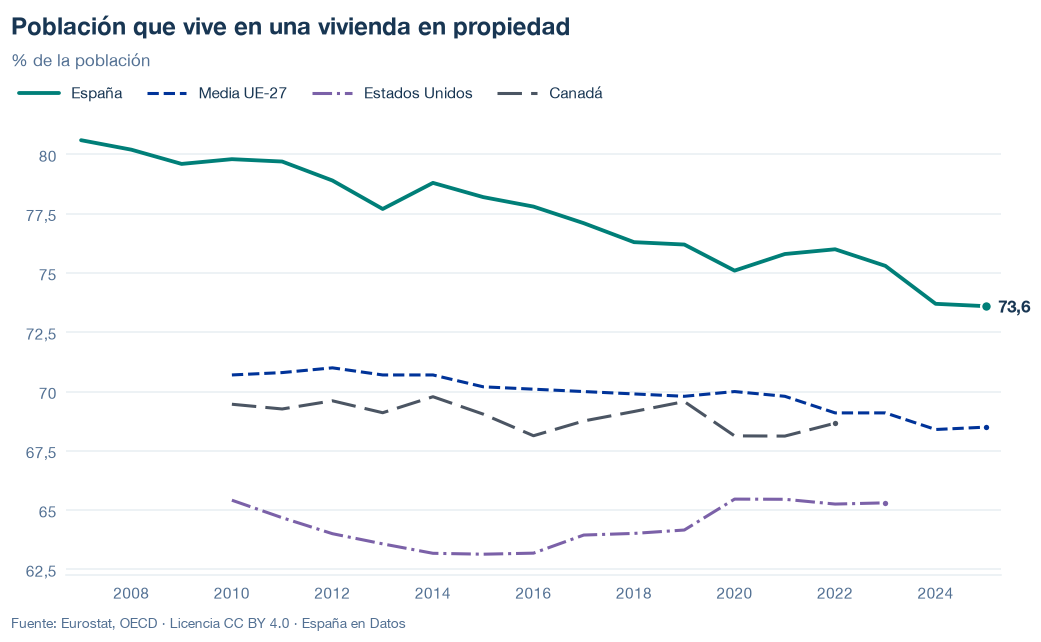

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/poblacion-vivienda-propiedad.json y data/poblacion-vivienda-propiedad.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_lvho02`.
- OECD Affordable Housing Database, HM1.3 (`HM1.3.A1`).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.